## FACULTY OF ENGINEERING, DESIGN AND TECHNOLOGY
## DEPARTMENT OF COMPUTING AND TECHNOLOGY
## COURSE NAME: Data Science Lifecycle

## ASSIGNMENT ONE

## Samuel_KAMUTUNGYE_B35097


### *Question 1.* Explore the features in the dataset that could be used to predict the price of a car. Check for missing values, duplicates and outliers, and handle any you find. Save the cleaned dataset as YourLastName Data.csv.

In [1]:
# Import libraries for data manipulation and analysis
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Configure pandas display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Set visualization style
sns.set_style("whitegrid")

In [2]:
# Import the automobile dataset

df = pd.read_csv(
    "automobileEDA.csv",
    na_values=["?", "NA", "N/A", "null", "NULL", ""]
)

# Display the first five records
print("First five observations:")
display(df.head())

# Display dataset dimensions
print("\nDataset dimensions:")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names
print("\nDataset variables:")
print(df.columns.tolist())

First five observations:


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1



Dataset dimensions:
Number of rows: 201
Number of columns: 29

Dataset variables:
['symboling', 'normalized-losses', 'make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'city-L/100km', 'horsepower-binned', 'diesel', 'gas']


In [3]:
# Identify the target variable
target = "price"

# Check whether the price column exists
if target not in df.columns:
    raise ValueError("The dataset does not contain a 'price' column.")

# Identify potential predictor variables
features = [column for column in df.columns if column != target]

print("Target variable:", target)

print("\nPotential predictor variables:")
for feature in features:
    print("-", feature)

# Display the data types of all variables
print("\nData types:")
print(df.dtypes)

# Generate dataset information
print("\nDataset information:")
df.info()

Target variable: price

Potential predictor variables:
- symboling
- normalized-losses
- make
- aspiration
- num-of-doors
- body-style
- drive-wheels
- engine-location
- wheel-base
- length
- width
- height
- curb-weight
- engine-type
- num-of-cylinders
- engine-size
- fuel-system
- bore
- stroke
- compression-ratio
- horsepower
- peak-rpm
- city-mpg
- highway-mpg
- city-L/100km
- horsepower-binned
- diesel
- gas

Data types:
symboling              int64
normalized-losses      int64
make                     str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                 float64
stroke               float64
compression-ratio  

In [4]:
# Calculate missing values in each column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Create a missing-value summary
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

# Display columns with missing values
print("Missing Value Summary:")
display(missing_summary[missing_summary["Missing Values"] > 0])

# Display total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

Missing Value Summary:


,Missing Values,Missing Percentage (%)
stroke,4,1.990050
horsepower-binned,1,0.497512



Total missing values: 5


In [5]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

# Remove duplicate records
df = df.drop_duplicates().copy()

# Confirm duplicates have been removed
print("Remaining duplicate records:", df.duplicated().sum())

# Display updated dataset dimensions
print("Updated dataset shape:", df.shape)

Number of duplicate records: 0
Remaining duplicate records: 0
Updated dataset shape: (201, 29)


In [7]:
# Remove columns that contain entirely missing values
empty_columns = df.columns[df.isnull().all()].tolist()

if empty_columns:
    print("Removing completely empty columns:", empty_columns)
    df = df.drop(columns=empty_columns)

# Remove records where car price is missing
df = df.dropna(subset=["price"]).copy()

# Ensure price is numeric
df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Remove invalid or missing price records
df = df.dropna(subset=["price"])
df = df[df["price"] > 0].copy()

# Identify numerical and categorical variables
numerical_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns

# Fill missing numerical values using the median
for column in numerical_columns:

    if df[column].isnull().sum() > 0:

        median_value = df[column].median()

        df[column] = df[column].fillna(median_value)

        print(f"{column}: Missing values filled using median.")

# Fill missing categorical values using the mode
for column in categorical_columns:

    if df[column].isnull().sum() > 0:

        mode_value = df[column].mode()

        if not mode_value.empty:
            df[column] = df[column].fillna(mode_value.iloc[0])

            print(f"{column}: Missing values filled using mode.")

print("\nMissing value handling completed.")


Missing value handling completed.


In [8]:
# Identify continuous numerical columns
# Exclude categorical codes with ten or fewer unique values.
continuous_columns = [
    column for column in df.select_dtypes(include=np.number).columns
    if df[column].nunique() > 10
]

# Create an outlier detection function
def detect_outliers(data, columns):

    outlier_results = []

    for column in columns:

        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[
            (data[column] < lower_bound) |
            (data[column] > upper_bound)
        ]

        outlier_results.append({
            "Variable": column,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Number of Outliers": len(outliers)
        })

    return pd.DataFrame(outlier_results)


# Detect outliers
outlier_summary = detect_outliers(df, continuous_columns)

print("Outlier Detection Summary:")
display(outlier_summary)

Outlier Detection Summary:


,Variable,Lower Bound,Upper Bound,Number of Outliers
0,normalized-losses,47.000000,191.000000,8
1,wheel-base,82.650000,114.250000,3
2,length,0.681163,1.002162,1
3,width,0.838194,0.977083,11
4,height,46.750000,60.750000,0
5,curb-weight,1033.500000,4061.500000,2
6,engine-size,33.500000,205.500000,10
7,bore,2.505000,4.225000,0
8,stroke,2.660000,3.860000,20
9,compression-ratio,7.400000,10.600000,27


In [9]:
# Create a copy of the original DataFrame
df_cleaned = df.copy()

# Check remaining missing values
print("Remaining missing values:")
print(df_cleaned.isnull().sum())

# Check duplicate records
print("\nRemaining duplicates:")
print(df_cleaned.duplicated().sum())

# Check dataset dimensions
print("\nCleaned dataset dimensions:")
print(df_cleaned.shape)

# Display the first five cleaned observations
print("\nCleaned dataset preview:")
display(df_cleaned.head())

# Display descriptive statistics
print("\nDescriptive statistics:")
display(df_cleaned.describe())

Remaining missing values:
symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    0
diesel               0
gas                  0
dtype: int64

Remaining duplicates:
0

Cleaned dataset dimensions:
(201, 29)

Cleaned dataset preview:


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1



Descriptive statistics:


,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
count,201.000000,201.00000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,0.840796,122.00000,98.797015,0.837102,0.915126,53.766667,2555.666667,126.875622,3.330692,3.257562,10.164279,103.405534,5117.665368,25.179104,30.686567,13207.129353,9.944145,0.099502,0.900498
std,1.254802,31.99625,6.066366,0.059213,0.029187,2.447822,517.296727,41.546834,0.268072,0.316082,4.004965,37.365700,478.113805,6.423220,6.815150,7947.066342,2.534599,0.300083,0.300083
min,-2.000000,65.00000,86.600000,0.678039,0.837500,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000,4.795918,0.000000,0.000000
25%,0.000000,101.00000,94.500000,0.801538,0.890278,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000,7.833333,0.000000,1.000000
50%,1.000000,122.00000,97.000000,0.832292,0.909722,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5125.369458,24.000000,30.000000,10295.000000,9.791667,0.000000,1.000000
75%,2.000000,137.00000,102.400000,0.881788,0.925000,55.500000,2926.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000,12.368421,0.000000,1.000000
max,3.000000,256.00000,120.900000,1.000000,1.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000,18.076923,1.000000,1.000000


In [10]:
# Save the cleaned automobile dataset as a CSV file

df_cleaned.to_csv(
    "Kamutungye_Data.csv",
    index=False
)

print("Cleaned automobile dataset saved successfully!")

Cleaned automobile dataset saved successfully!


### *Question 2.* Analyse patterns and run descriptive statistics on the dataset. Give summary statistics for the continuous variables and frequency counts for the categorical variables. Use graphs to show how price and the other variables are distributed and summarize the findings on the patterns observed.

In [11]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

# Load the cleaned automobile dataset
df = pd.read_csv("Kamutungye_Data.csv")

# Display first five records
display(df.head())

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display dataset information
df.info()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


Dataset shape: (201, 29)
<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system 

In [12]:
# Identify continuous numerical variables
continuous_vars = [
    col for col in df.select_dtypes(include=np.number).columns
    if df[col].nunique() > 10
]

# Identify categorical variables
categorical_vars = (
    df.select_dtypes(include=["object", "category", "string"]).columns.tolist()
    +
    [
        col for col in df.select_dtypes(include=np.number).columns
        if df[col].nunique() <= 10
    ]
)

print("CONTINUOUS VARIABLES:")
print(continuous_vars)

print("\nCATEGORICAL VARIABLES:")
print(categorical_vars)

CONTINUOUS VARIABLES:
['normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'city-L/100km']

CATEGORICAL VARIABLES:
['make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system', 'horsepower-binned', 'symboling', 'diesel', 'gas']


In [13]:
# Generate descriptive statistics for continuous variables
continuous_summary = df[continuous_vars].describe().T

# Add median and variance
continuous_summary["Median"] = df[continuous_vars].median()
continuous_summary["Variance"] = df[continuous_vars].var()

# Display results
print("SUMMARY STATISTICS FOR CONTINUOUS VARIABLES")

display(continuous_summary.round(2))

SUMMARY STATISTICS FOR CONTINUOUS VARIABLES


,count,mean,std,min,25%,50%,75%,max,Median,Variance
normalized-losses,201.0,122.00,32.00,65.00,101.00,122.00,137.00,256.00,122.00,1023.76
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90,97.00,36.80
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00,0.83,0.00
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00,0.91,0.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80,54.10,5.99
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00,2414.00,267595.90
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00,120.00,1726.14
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94,3.31,0.07
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17,3.29,0.10
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00,9.00,16.04


In [14]:
# Calculate frequency counts for each categorical variable

for column in categorical_vars:

    print("\nFrequency distribution:", column)

    frequency = df[column].value_counts(dropna=False)

    display(frequency.to_frame(name="Frequency"))


Frequency distribution: make


,Frequency
make,
toyota,32
nissan,18
mazda,17
honda,13
mitsubishi,13
subaru,12
volkswagen,12
peugot,11
volvo,11



Frequency distribution: aspiration


,Frequency
aspiration,
std,165
turbo,36



Frequency distribution: num-of-doors


,Frequency
num-of-doors,
four,115
two,86


... (16 outputs left out)


Frequency distribution: diesel


,Frequency
diesel,
0,181
1,20



Frequency distribution: gas


,Frequency
gas,
1,181
0,20


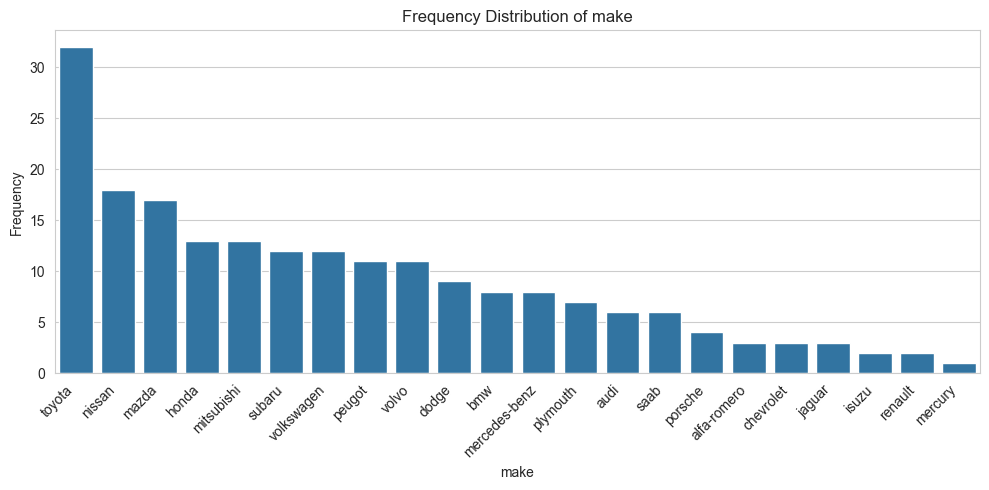

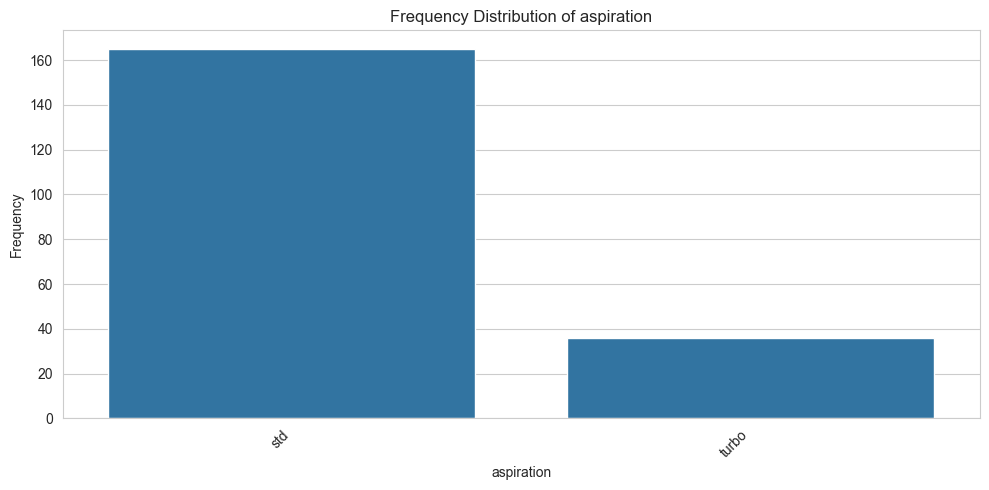

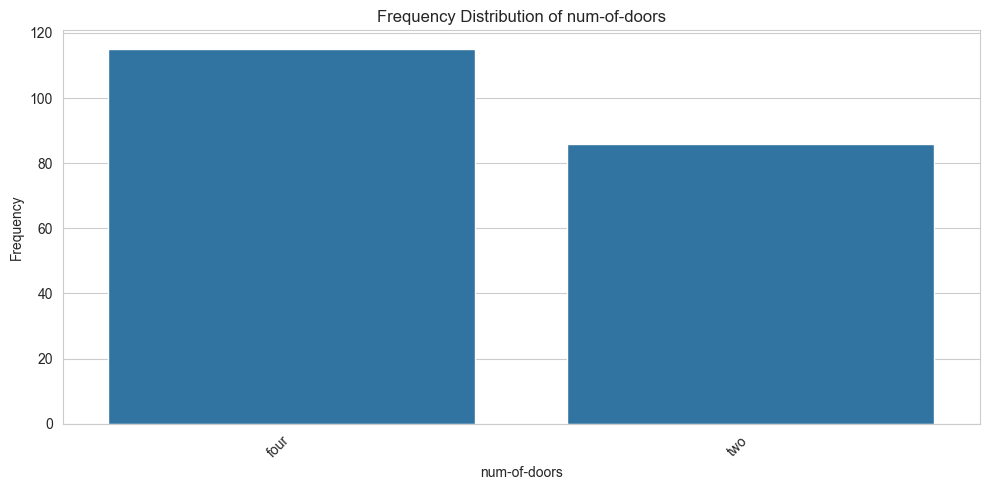

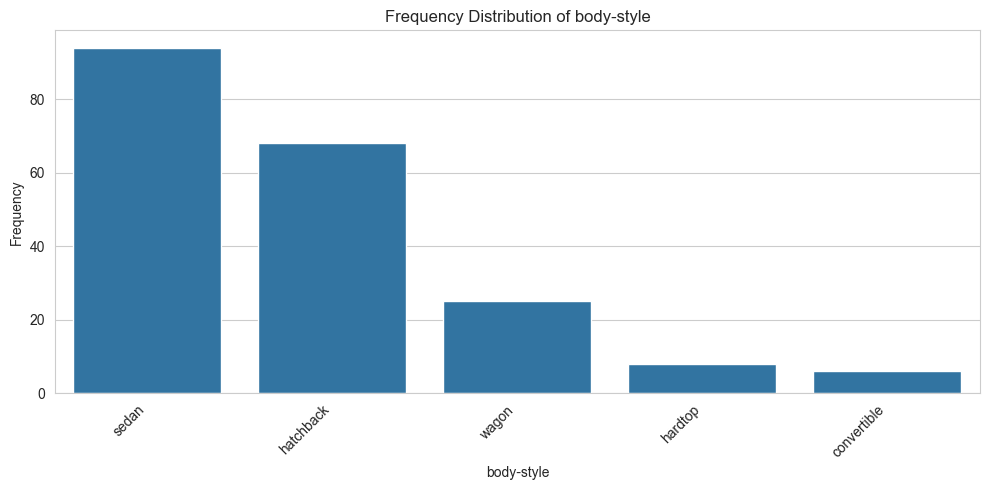

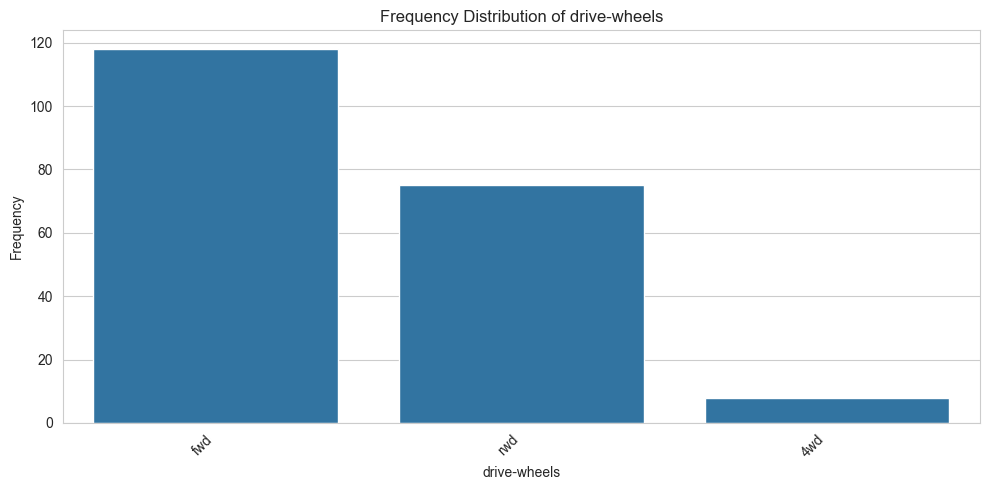

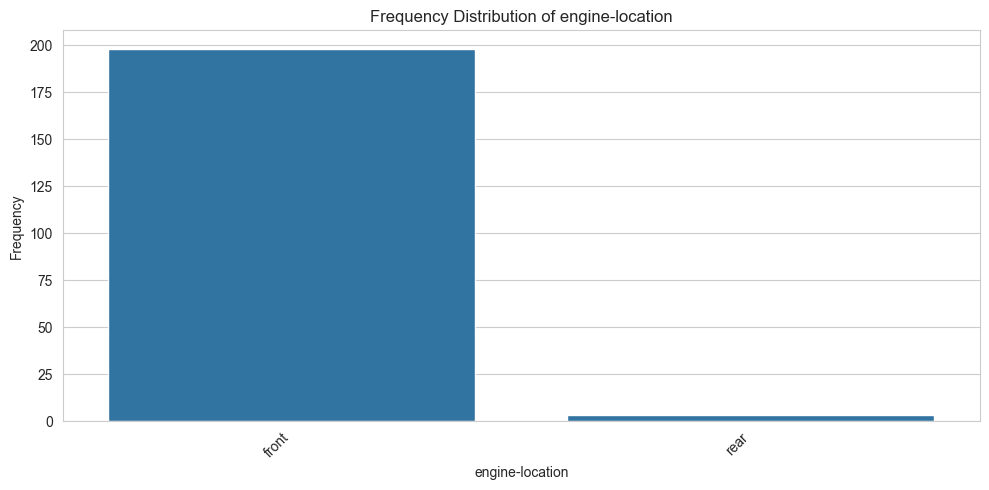

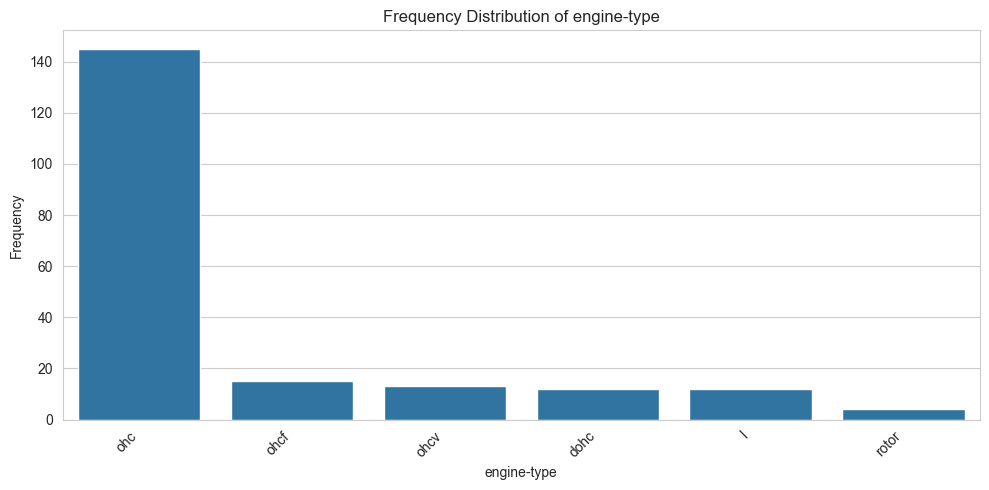

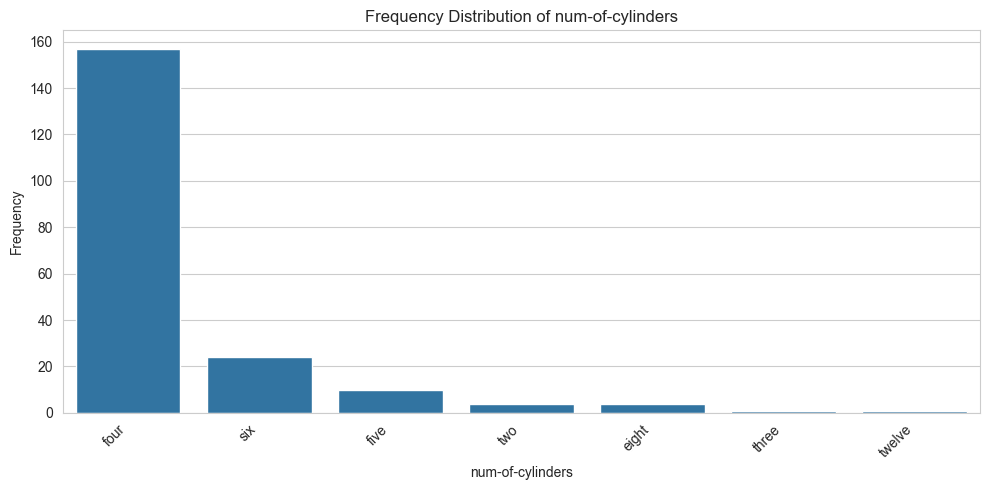

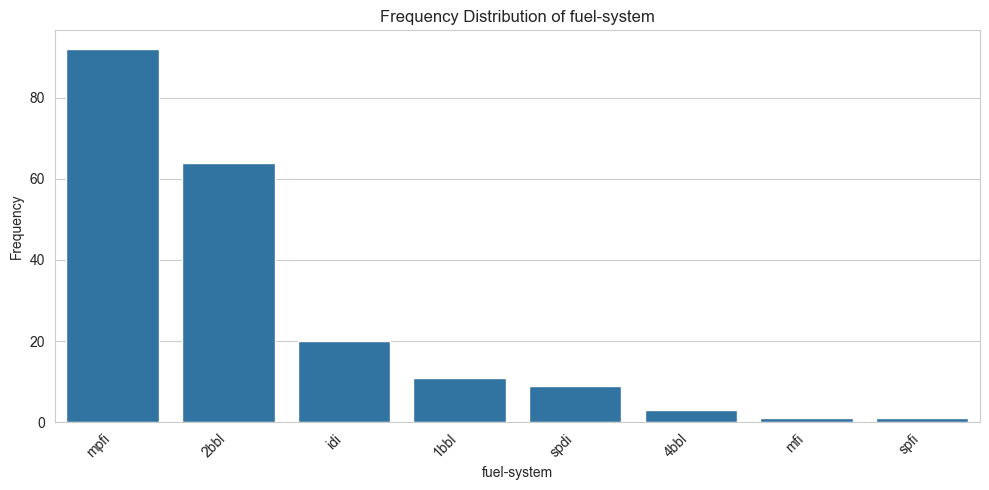

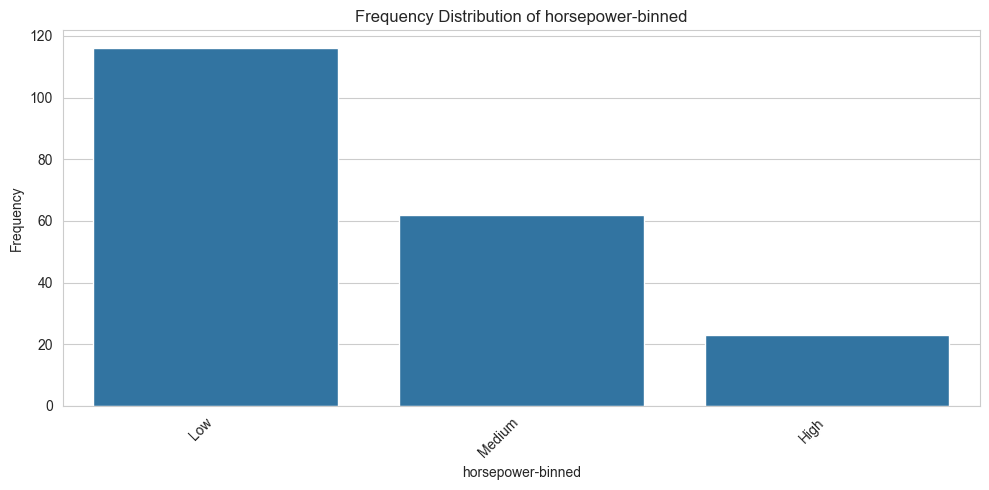

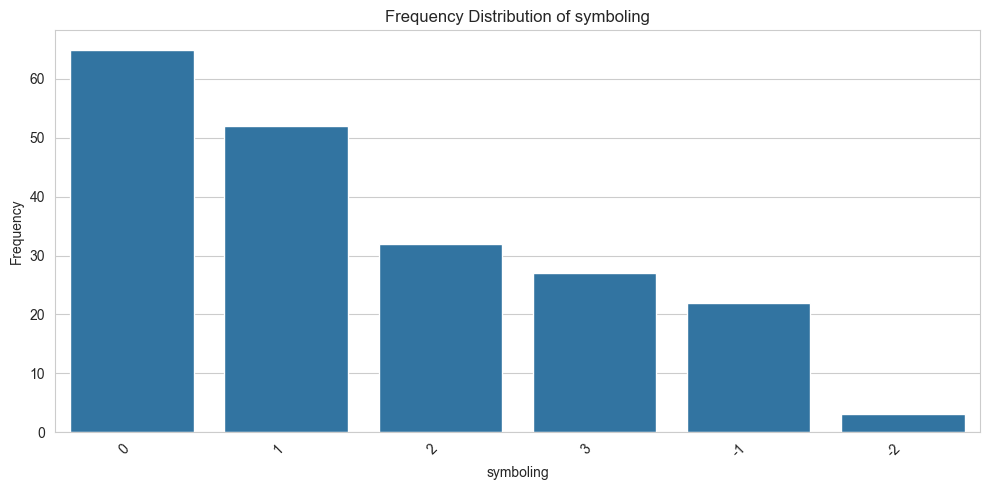

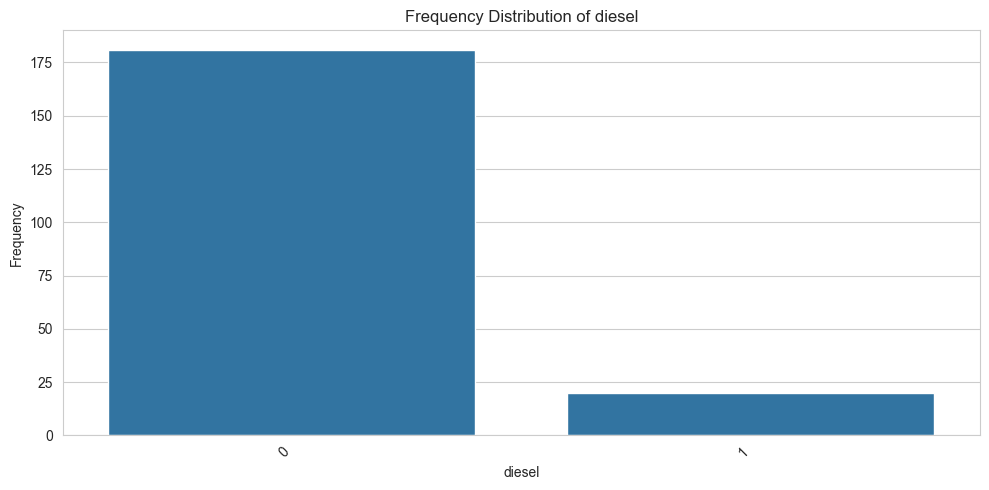

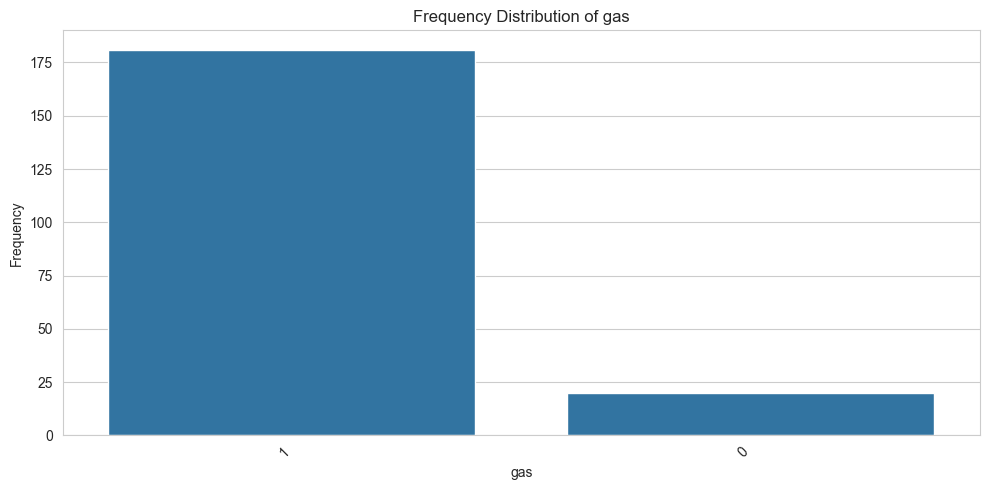

In [15]:
# Generate bar charts for categorical variables

for column in categorical_vars:

    plt.figure(figsize=(10, 5))

    order = df[column].value_counts().index

    sns.countplot(
        data=df,
        x=column,
        order=order
    )

    plt.title(f"Frequency Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

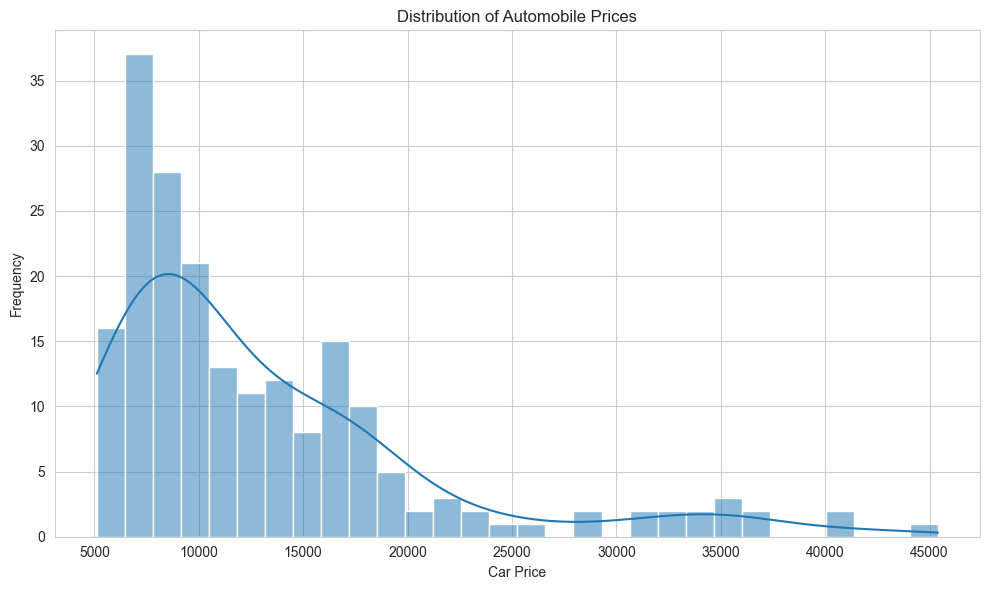

In [16]:
# Plot the distribution of car prices

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price",
    bins=30,
    kde=True
)

plt.title("Distribution of Automobile Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

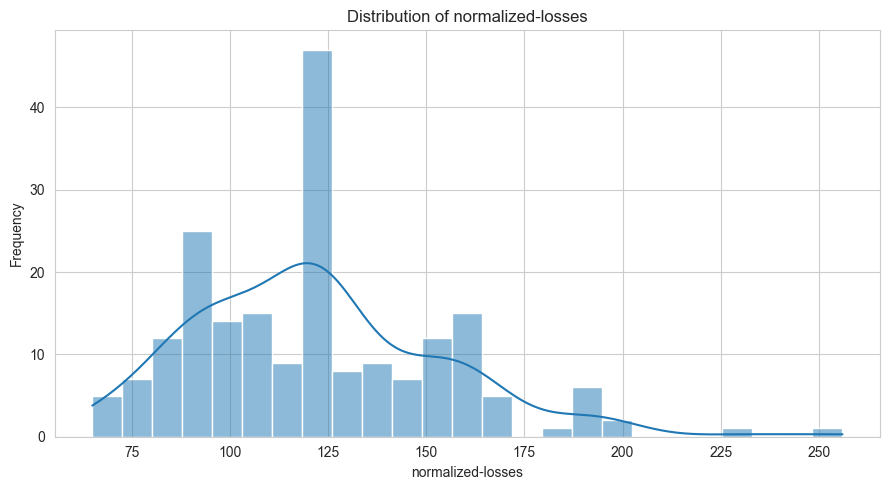

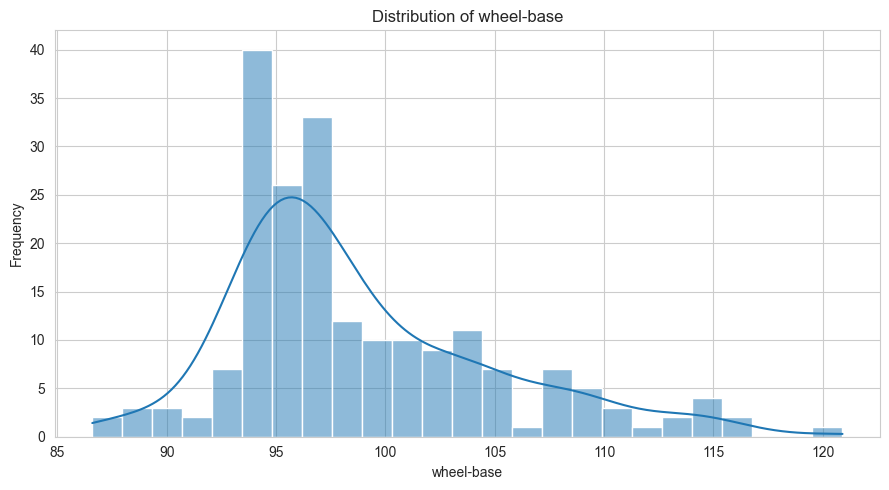

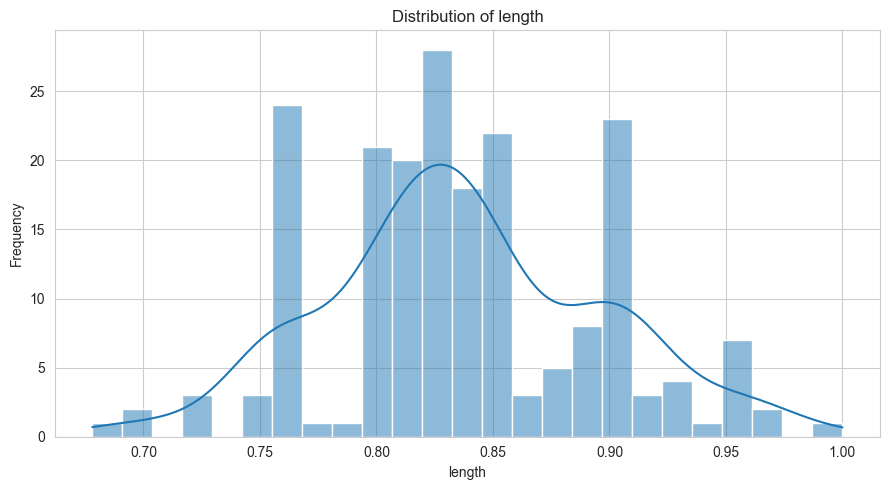

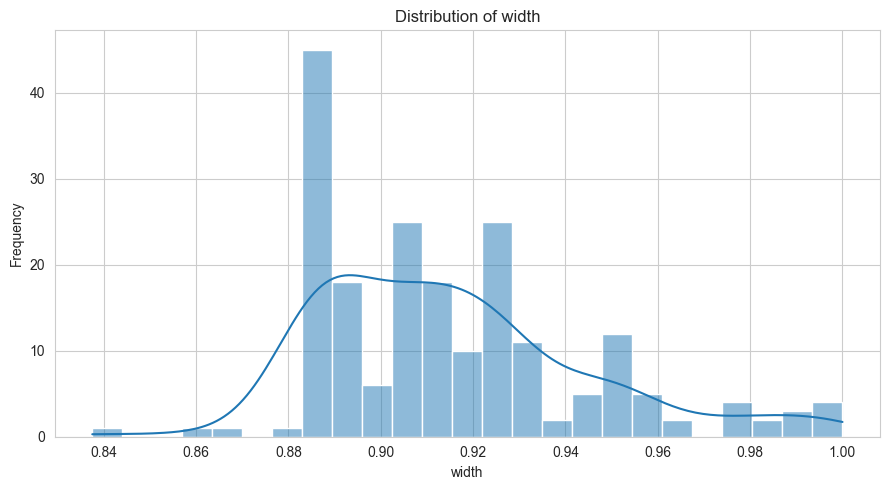

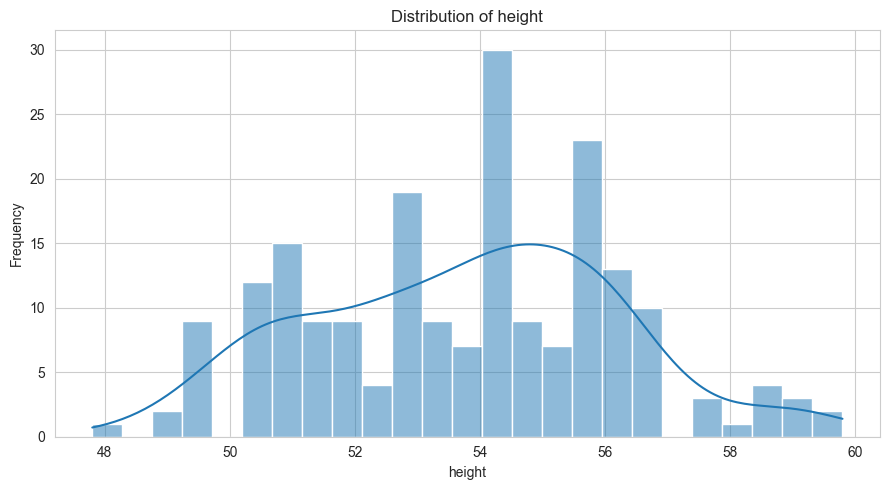

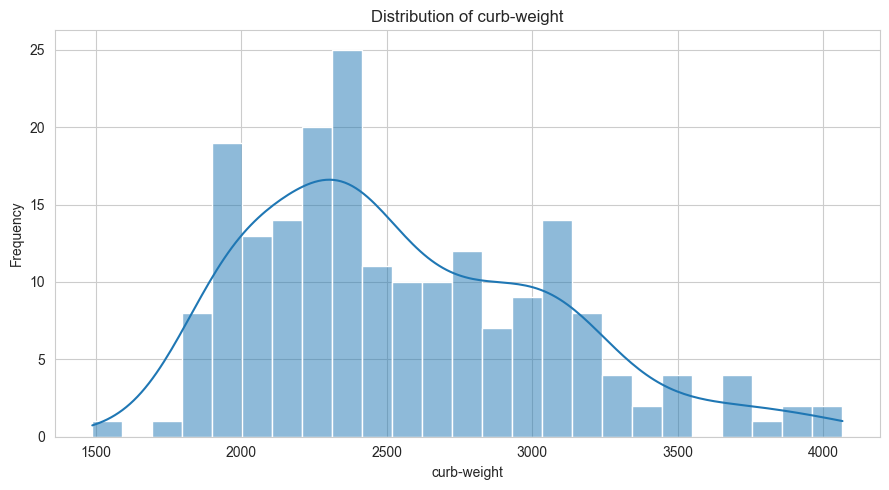

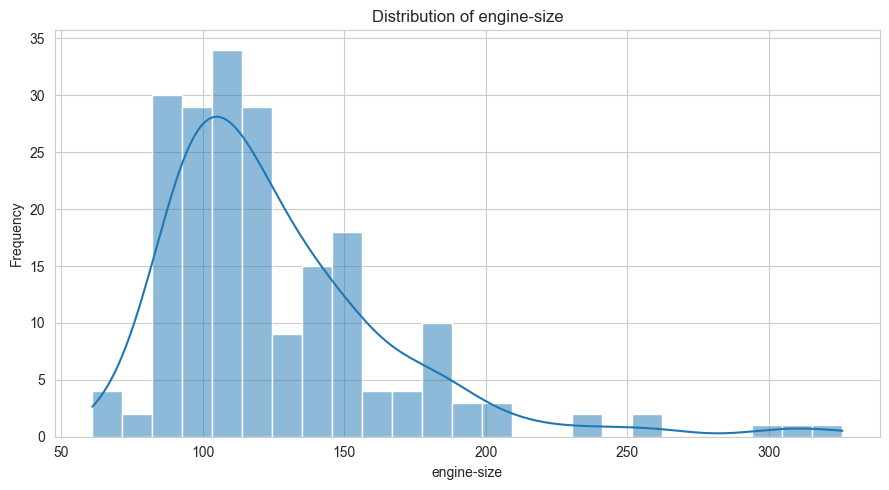

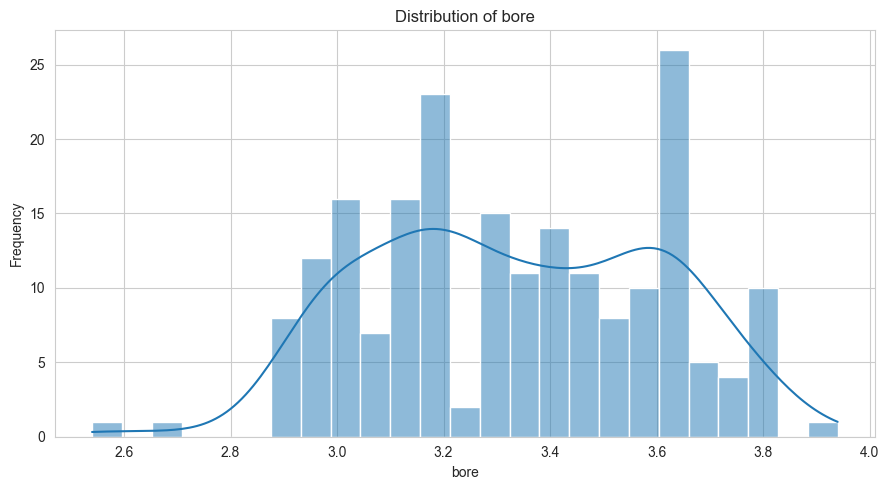

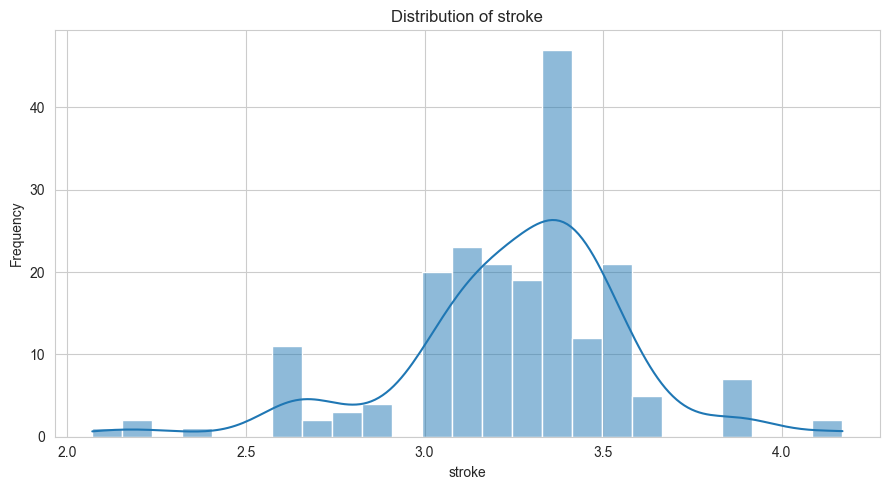

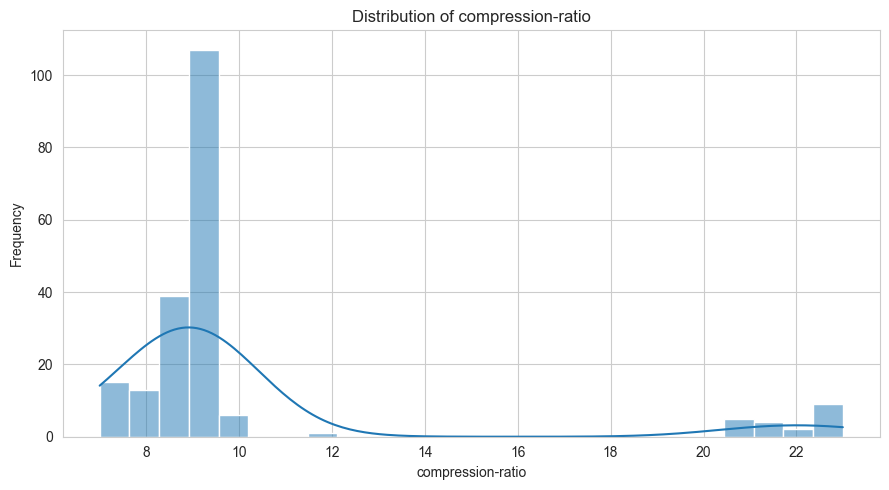

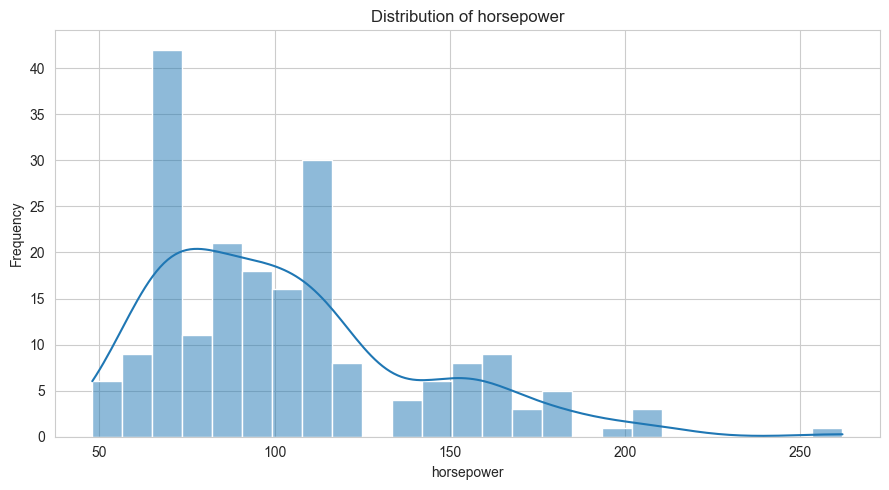

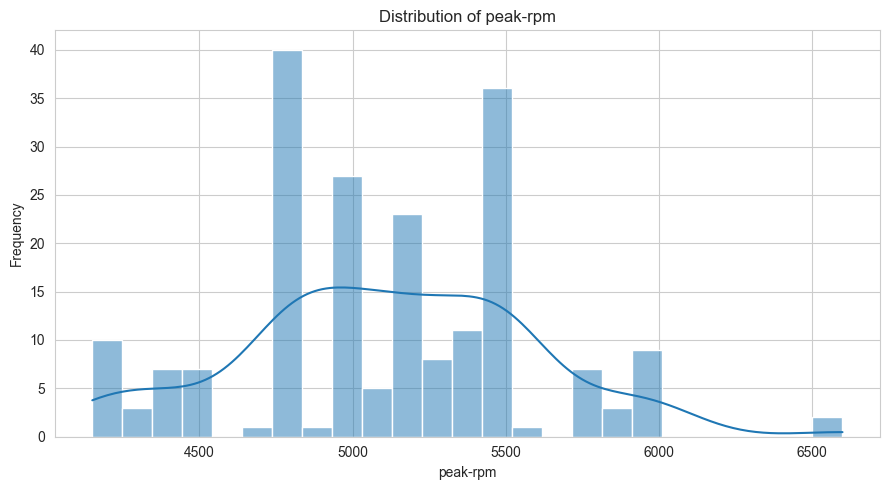

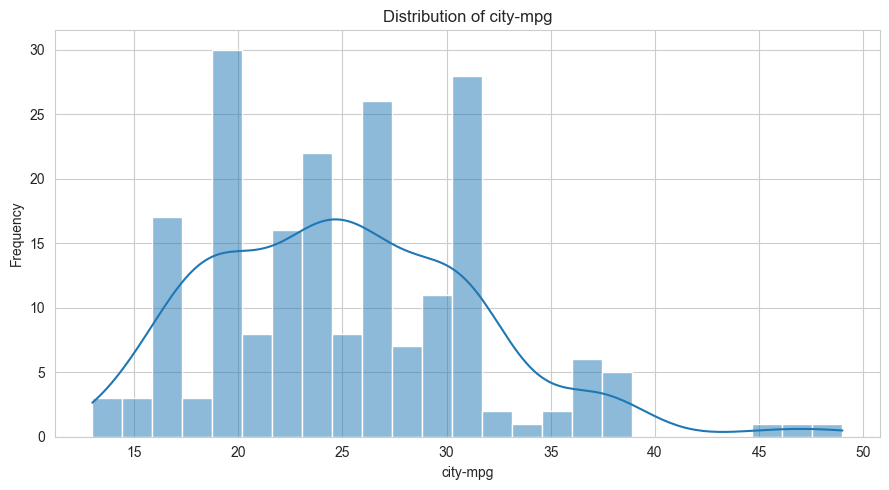

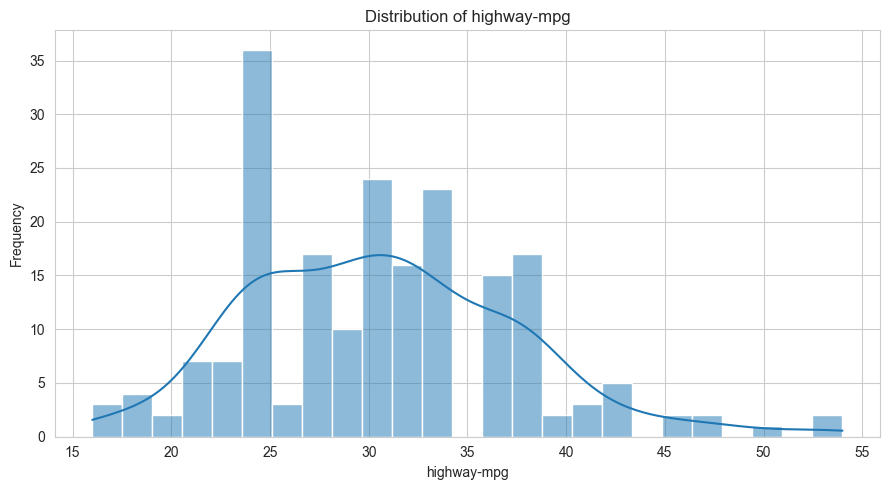

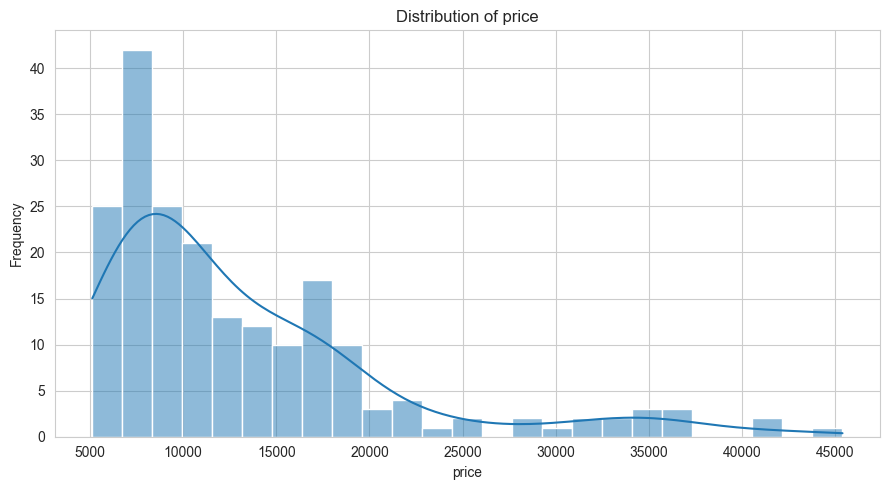

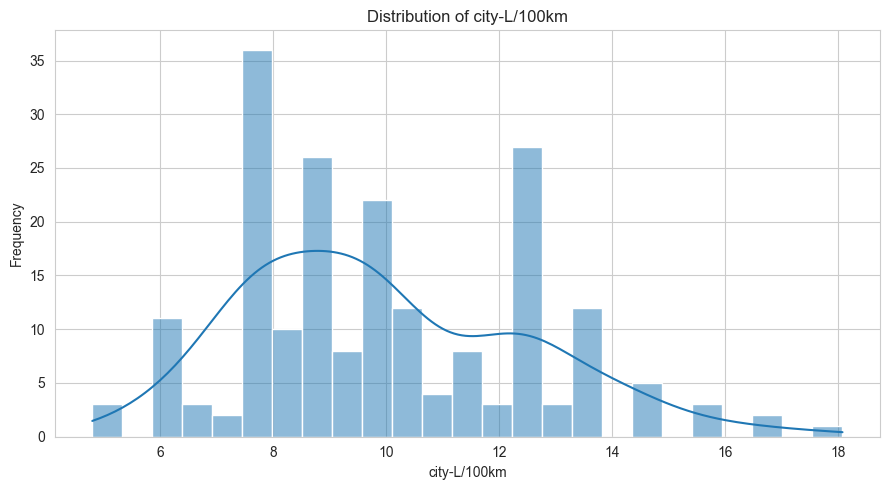

In [18]:
# Plot histograms for all continuous variables

for column in continuous_vars:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df,
        x=column,
        bins=25,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

Correlation of variables with car price:


,Correlation with Price
price,1.000000
engine-size,0.872335
curb-weight,0.834415
horsepower,0.809575
city-L/100km,0.789898
width,0.751265
length,0.690628
wheel-base,0.584642
bore,0.543155
height,0.135486


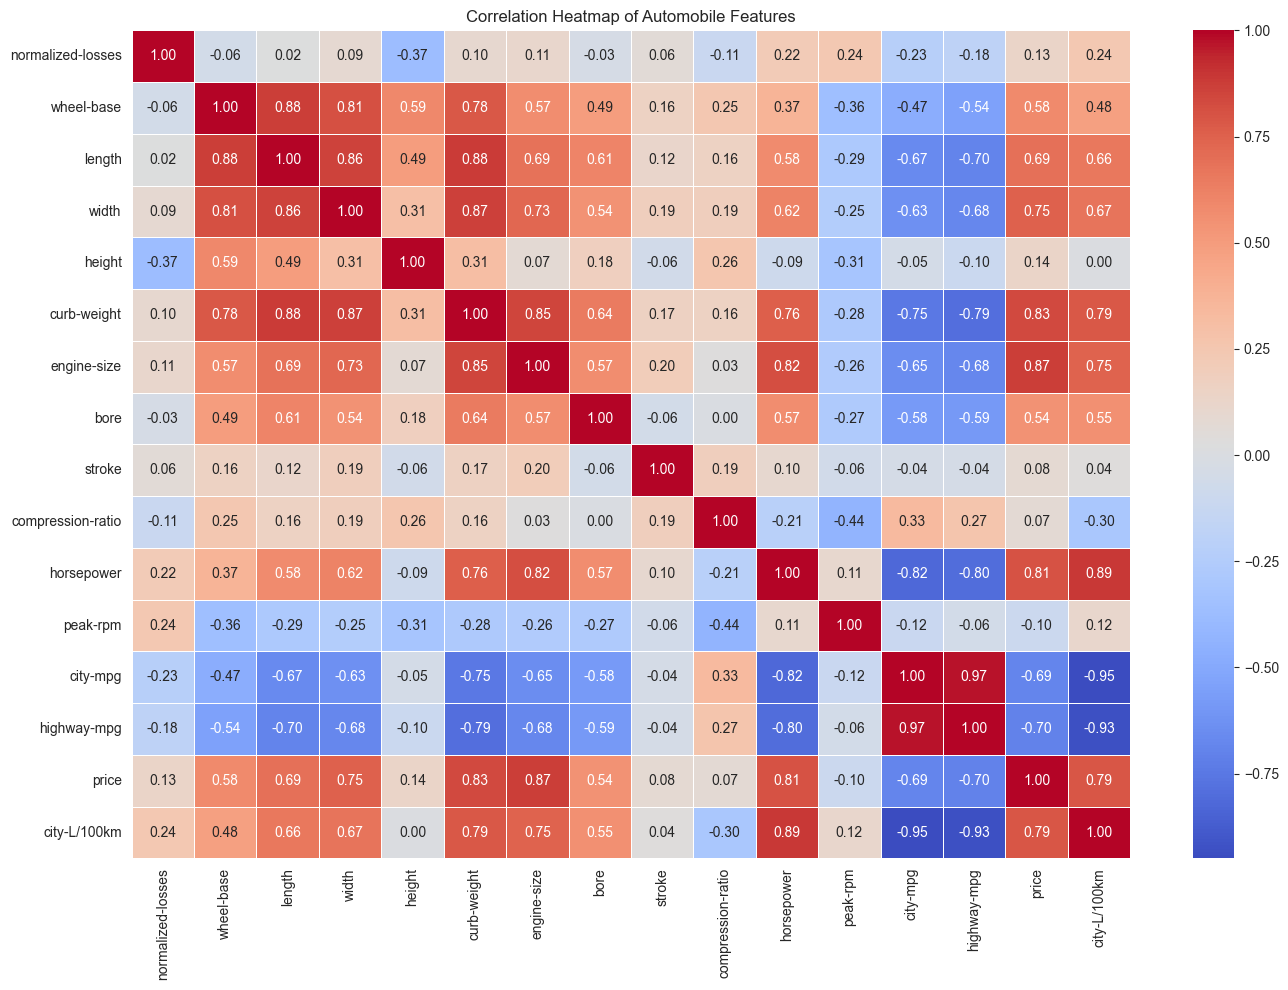

In [20]:
# Calculate correlation between numerical variables
correlation_matrix = df[continuous_vars].corr()

# Display correlation with price
price_correlation = correlation_matrix["price"].sort_values(
    ascending=False
)

print("Correlation of variables with car price:")
display(price_correlation.to_frame(name="Correlation with Price"))

# Generate correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Automobile Features")

plt.tight_layout()
plt.show()

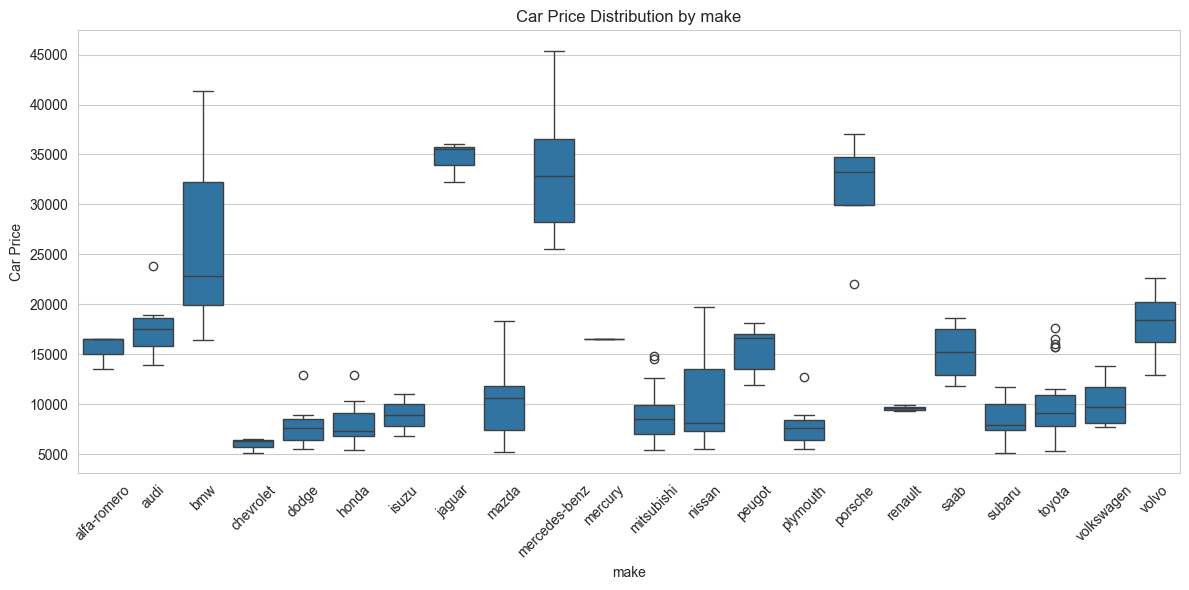

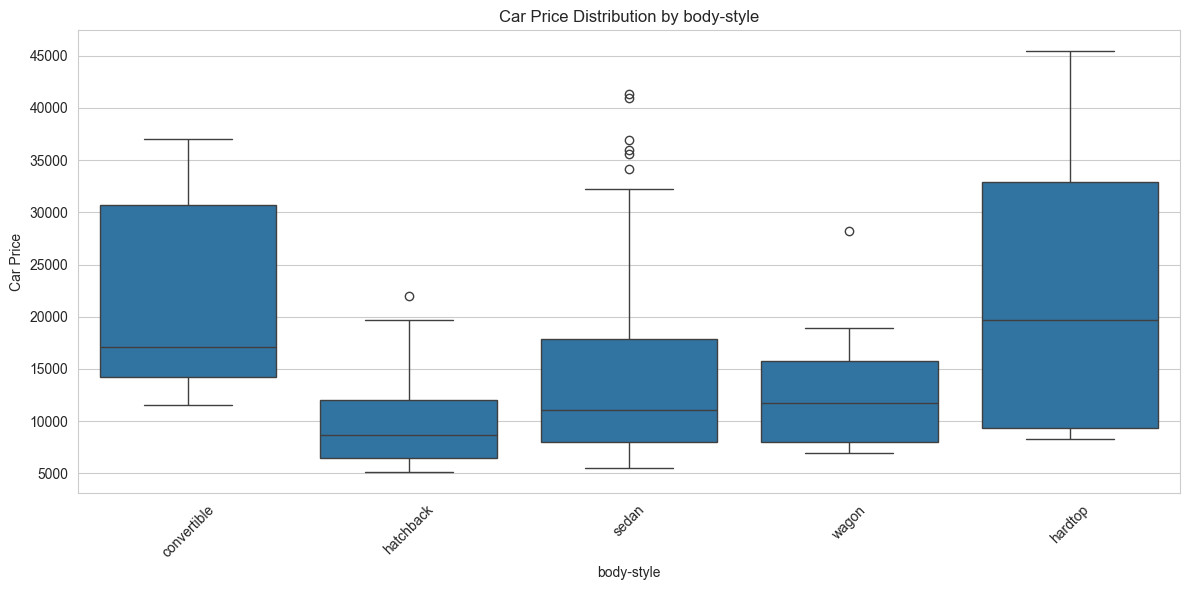

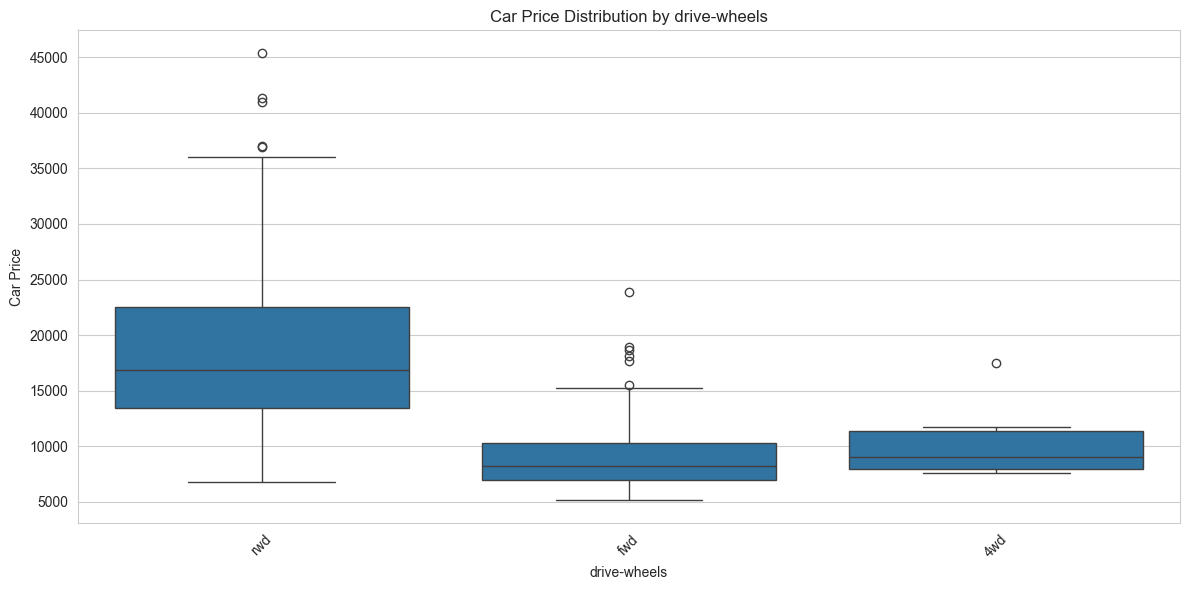

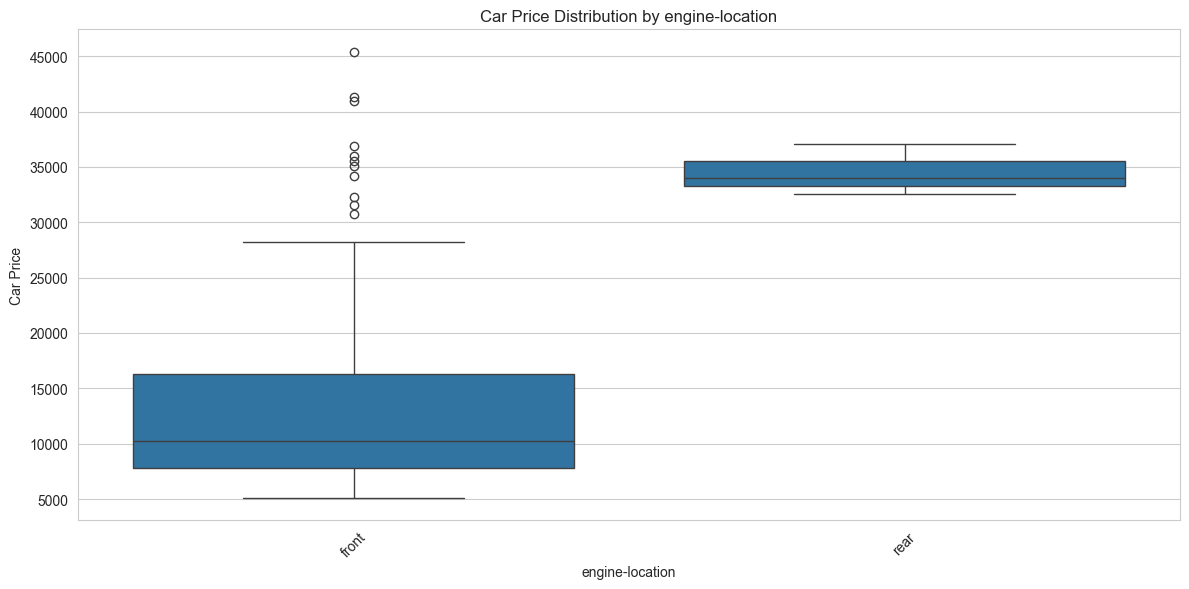

In [21]:
# Select useful categorical features for price comparison

categorical_features = [
    col for col in ["make", "fuel-type", "body-style",
                    "drive-wheels", "engine-location"]
    if col in df.columns
]

# Generate boxplots for categorical variables against price

for column in categorical_features:

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=df,
        x=column,
        y="price"
    )

    plt.title(f"Car Price Distribution by {column}")
    plt.xlabel(column)
    plt.ylabel("Car Price")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### *Question 3.* Group the data by identified parameters, such as drive-wheels and body-style. Find the average price for each group and present the results using visuals and statistics. Which groups have the highest and lowest prices?

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned automobile dataset
df = pd.read_csv("Kamutungye_Data.csv")

# Display relevant columns
print(df[["drive-wheels", "body-style", "price"]].head())

  drive-wheels   body-style    price
0          rwd  convertible  13495.0
1          rwd  convertible  16500.0
2          rwd    hatchback  16500.0
3          fwd        sedan  13950.0
4          4wd        sedan  17450.0


In [23]:
#Calculate the average, minimum, maximum and number of vehicles for each drive-wheel group.

drive_wheels_stats = df.groupby("drive-wheels")["price"].agg(
    Average_Price="mean",
    Minimum_Price="min",
    Maximum_Price="max",
    Number_of_Cars="count"
).round(2)

print("Average Price by Drive-Wheels:")
display(drive_wheels_stats)

Average Price by Drive-Wheels:


,Average_Price,Minimum_Price,Maximum_Price,Number_of_Cars
drive-wheels,,,,
4wd,10241.00,7603.0,17450.0,8
fwd,9244.78,5118.0,23875.0,118
rwd,19757.61,6785.0,45400.0,75


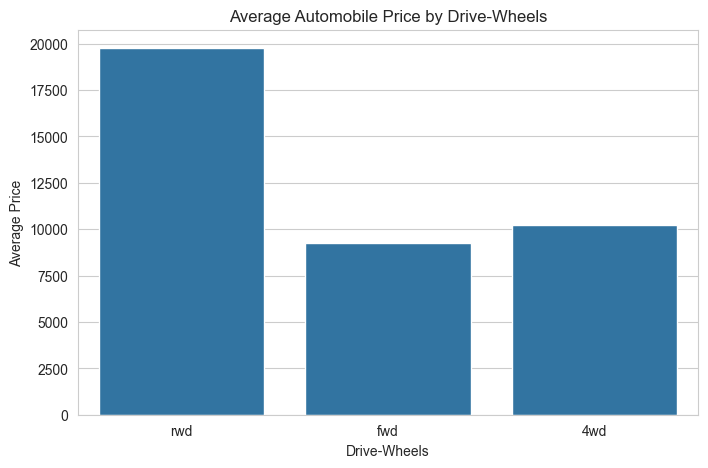

In [24]:
#Visualisation: Average price by drive-wheels

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="drive-wheels",
    y="price",
    estimator="mean",
    errorbar=None
)

plt.title("Average Automobile Price by Drive-Wheels")
plt.xlabel("Drive-Wheels")
plt.ylabel("Average Price")
plt.show()

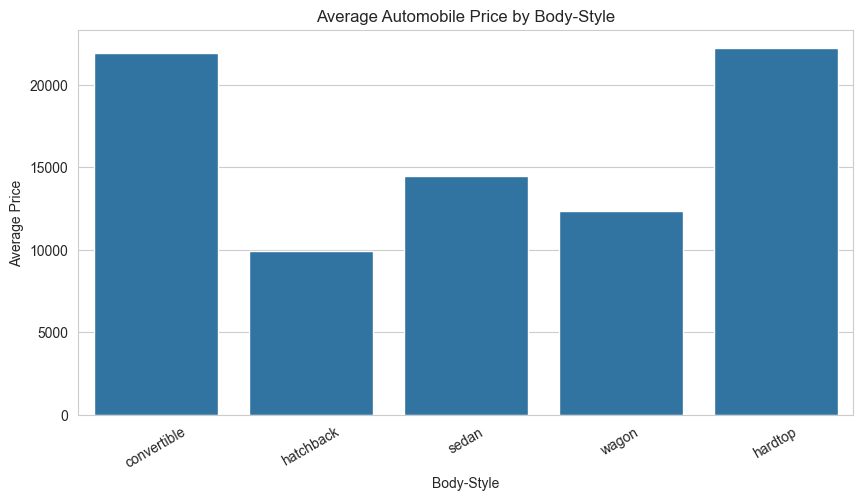

In [25]:
#Average price by body-style

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="body-style",
    y="price",
    estimator="mean",
    errorbar=None
)

plt.title("Average Automobile Price by Body-Style")
plt.xlabel("Body-Style")
plt.ylabel("Average Price")
plt.xticks(rotation=30)
plt.show()

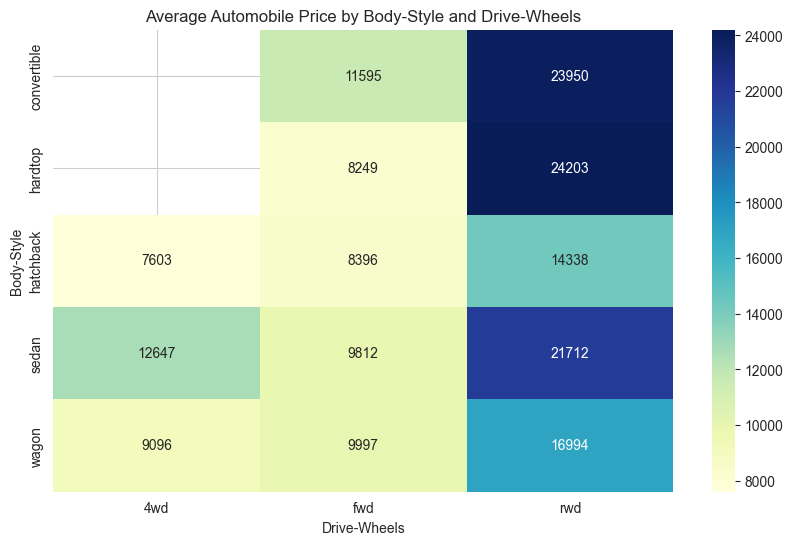

In [26]:
#Combined comparison using a heatmap

price_pivot = df.pivot_table(
    values="price",
    index="body-style",
    columns="drive-wheels",
    aggfunc="mean"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    price_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Average Automobile Price by Body-Style and Drive-Wheels")
plt.xlabel("Drive-Wheels")
plt.ylabel("Body-Style")
plt.show()

In [27]:
# Highest and lowest average prices by drive-wheels
highest_drive = drive_wheels_stats["Average_Price"].idxmax()
lowest_drive = drive_wheels_stats["Average_Price"].idxmin()

# Highest and lowest average prices by body-style
body_style_stats = df.groupby("body-style")["price"].agg(
    Average_Price="mean",
    Minimum_Price="min",
    Maximum_Price="max",
    Number_of_Cars="count"
).round(2)

highest_body = body_style_stats["Average_Price"].idxmax()

combined_stats = (
    df.groupby(["body-style", "drive-wheels"])["price"]
      .mean()
      .rename("Average_Price")
      .reset_index()
)
lowest_body = body_style_stats["Average_Price"].idxmin()

# Highest and lowest combined groups
highest_combined = combined_stats.loc[
    combined_stats["Average_Price"].idxmax()
]

lowest_combined = combined_stats.loc[
    combined_stats["Average_Price"].idxmin()
]

print("DRIVE-WHEELS")
print("Highest:", highest_drive,
      drive_wheels_stats.loc[highest_drive, "Average_Price"])
print("Lowest:", lowest_drive,
      drive_wheels_stats.loc[lowest_drive, "Average_Price"])

print("\nBODY-STYLE")
print("Highest:", highest_body,
      body_style_stats.loc[highest_body, "Average_Price"])
print("Lowest:", lowest_body,
      body_style_stats.loc[lowest_body, "Average_Price"])

print("\nCOMBINED GROUPS")
print("Highest-priced group:")
display(highest_combined)

print("Lowest-priced group:")
display(lowest_combined)

DRIVE-WHEELS
Highest: rwd 19757.61
Lowest: fwd 9244.78

BODY-STYLE
Highest: hardtop 22208.5
Lowest: hatchback 9957.44

COMBINED GROUPS
Highest-priced group:


body-style            hardtop
drive-wheels              rwd
Average_Price    24202.714286
Name: 3, dtype: object

Lowest-priced group:


body-style       hatchback
drive-wheels           4wd
Average_Price       7603.0
Name: 4, dtype: object

### *Question 4.* Identify the effect of the independent attributes on price using visuals and statistics. 
a) Continuous variables vs. price 
b) Categorical variables vs. price 
c) Two categorical variables

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned automobile dataset
df = pd.read_csv("Kamutungye_Data.csv")

sns.set_theme(style="whitegrid")

# Confirm dataset structure
print(df.head())
print(df.info())

   symboling  normalized-losses         make aspiration num-of-doors  \
0          3                122  alfa-romero        std          two   
1          3                122  alfa-romero        std          two   
2          1                122  alfa-romero        std          two   
3          2                164         audi        std         four   
4          2                164         audi        std         four   

    body-style drive-wheels engine-location  wheel-base    length     width  \
0  convertible          rwd           front        88.6  0.811148  0.890278   
1  convertible          rwd           front        88.6  0.811148  0.890278   
2    hatchback          rwd           front        94.5  0.822681  0.909722   
3        sedan          fwd           front        99.8  0.848630  0.919444   
4        sedan          4wd           front        99.4  0.848630  0.922222   

   height  curb-weight engine-type num-of-cylinders  engine-size fuel-system  \
0    48.8   

#### (a) Continuous variables versus price

In [30]:
# Select continuous numerical variables
continuous_vars = [
    col for col in df.select_dtypes(include=np.number).columns
    if col != "price" and df[col].nunique() > 10
]

# Calculate correlation with price
correlation = df[continuous_vars + ["price"]].corr(numeric_only=True)

price_correlation = correlation["price"].drop("price").sort_values(
    ascending=False
)

print("Correlation of continuous variables with price:")
display(price_correlation.to_frame("Correlation with Price"))

Correlation of continuous variables with price:


,Correlation with Price
engine-size,0.872335
curb-weight,0.834415
horsepower,0.809575
city-L/100km,0.789898
width,0.751265
length,0.690628
wheel-base,0.584642
bore,0.543155
height,0.135486
normalized-losses,0.133999


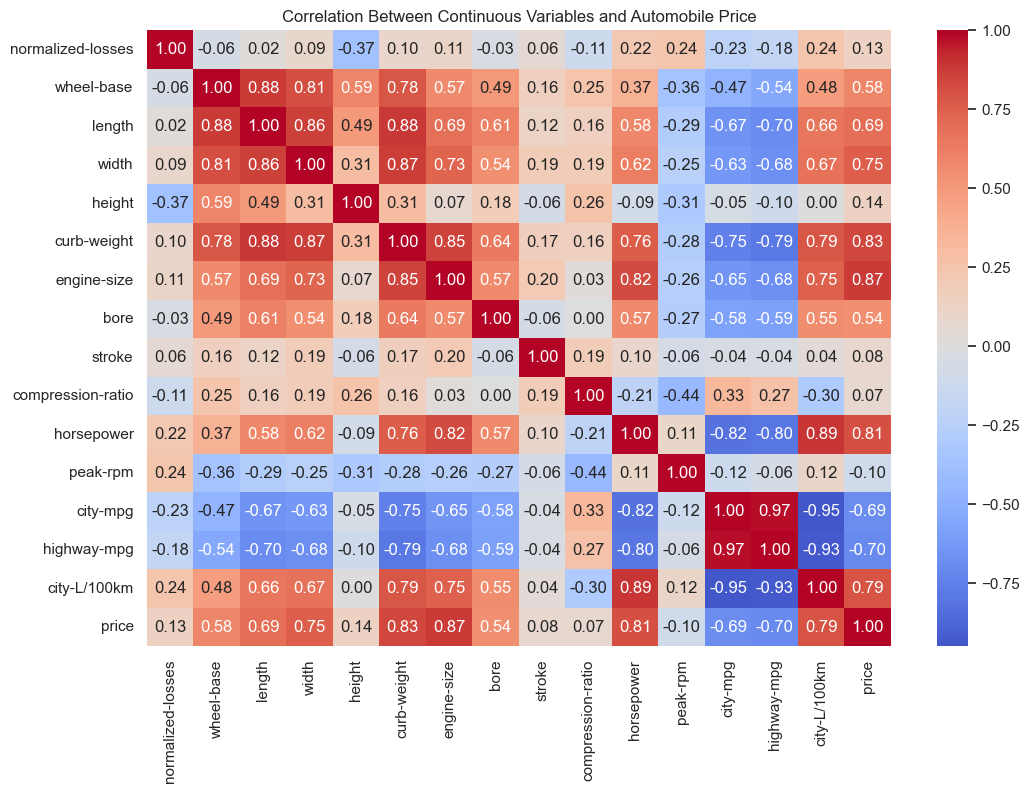

In [31]:
#Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Continuous Variables and Automobile Price")
plt.show()

#### (b) Categorical variables versus price

In [33]:
# Identify categorical variables
categorical_vars = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Calculate average price for each category
for column in categorical_vars:

    print(f"\nAverage Price by {column}:")

    category_stats = df.groupby(column, observed=True)["price"].agg(
        Average_Price="mean",
        Median_Price="median",
        Number_of_Cars="count"
    ).round(2)

    display(category_stats.sort_values(
        by="Average_Price",
        ascending=False
    ))


Average Price by make:


,Average_Price,Median_Price,Number_of_Cars
make,,,
jaguar,34600.00,35550.0,3
mercedes-benz,33647.00,32892.0,8
porsche,31400.50,33278.0,4
bmw,26118.75,22835.0,8
volvo,18063.18,18420.0,11
audi,17859.17,17580.0,6
mercury,16503.00,16503.0,1
alfa-romero,15498.33,16500.0,3
peugot,15489.09,16630.0,11



Average Price by aspiration:


,Average_Price,Median_Price,Number_of_Cars
aspiration,,,
turbo,16254.81,15686.0,36
std,12542.18,9538.0,165



Average Price by num-of-doors:


,Average_Price,Median_Price,Number_of_Cars
num-of-doors,,,
four,13498.03,10898.0,115
two,12818.13,9927.0,86


... (10 outputs left out)


Average Price by fuel-system:


,Average_Price,Median_Price,Number_of_Cars
fuel-system,,,
mpfi,17605.14,15867.5,92
idi,15838.15,13852.5,20
mfi,12964.00,12964.0,1
4bbl,12145.00,11845.0,3
spfi,11048.00,11048.0,1
spdi,10990.44,9959.0,9
1bbl,7555.55,7295.0,11
2bbl,7433.20,7324.0,64



Average Price by horsepower-binned:


,Average_Price,Median_Price,Number_of_Cars
horsepower-binned,,,
High,25899.13,19045.0,23
Medium,15913.02,14444.0,62
Low,9244.36,8006.0,116


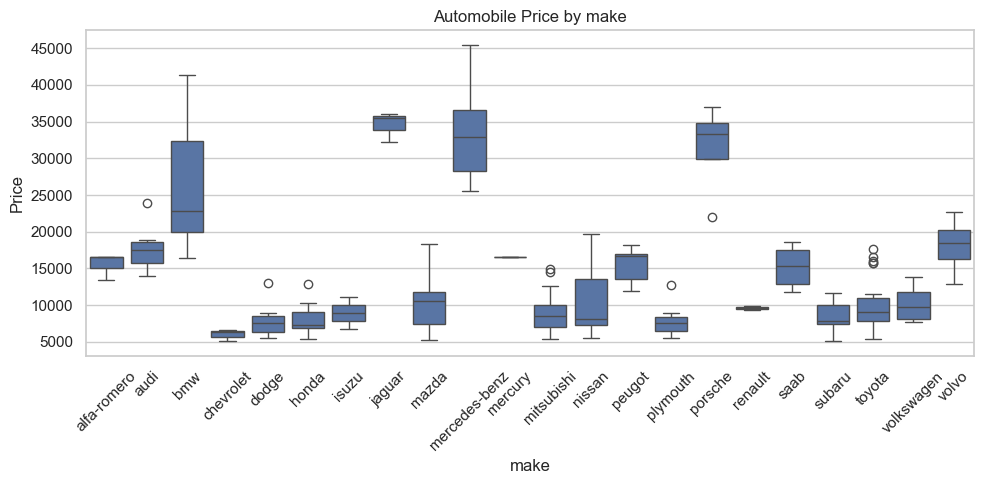

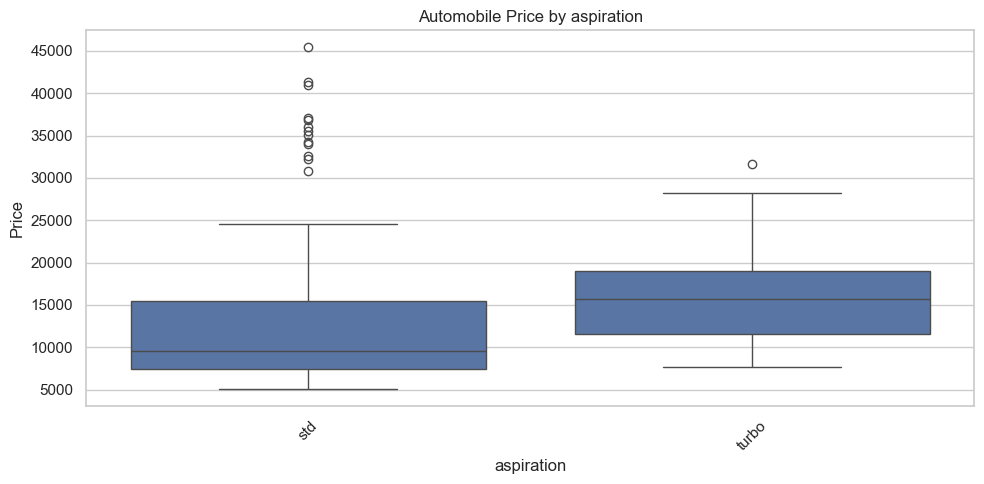

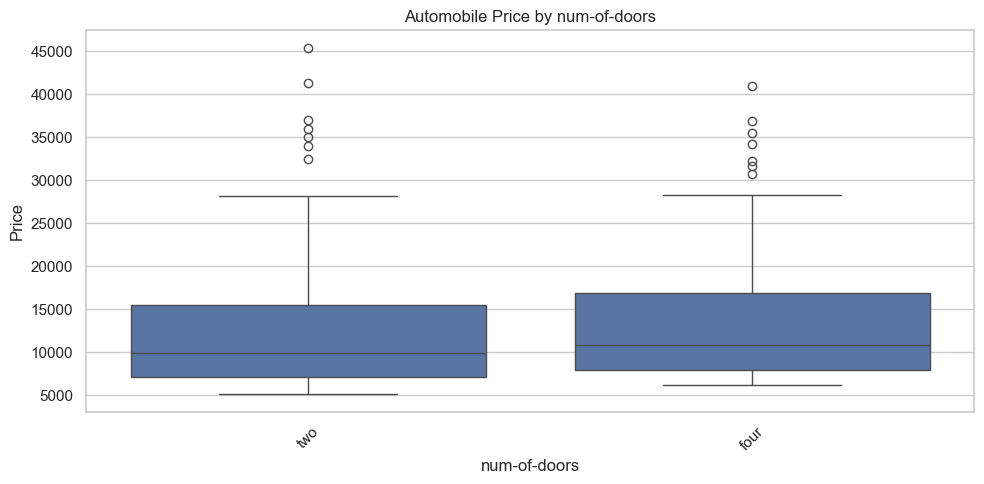

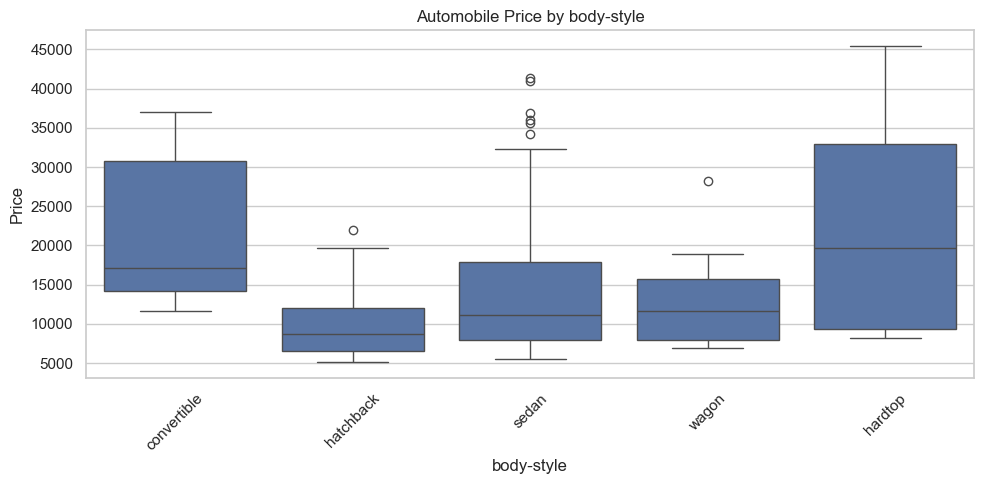

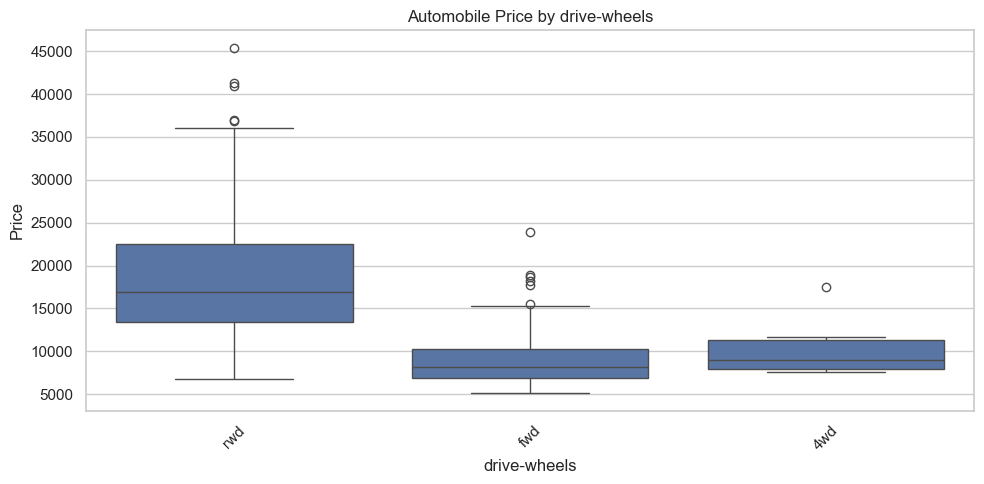

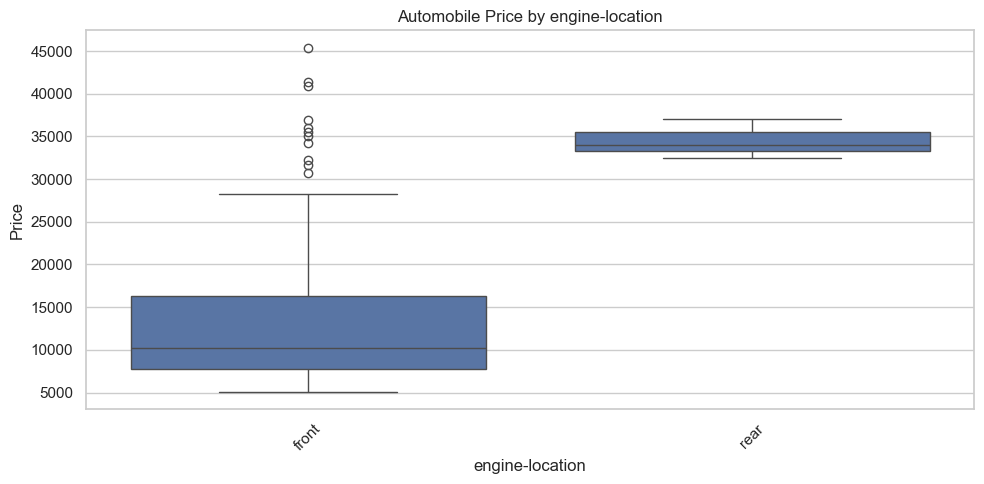

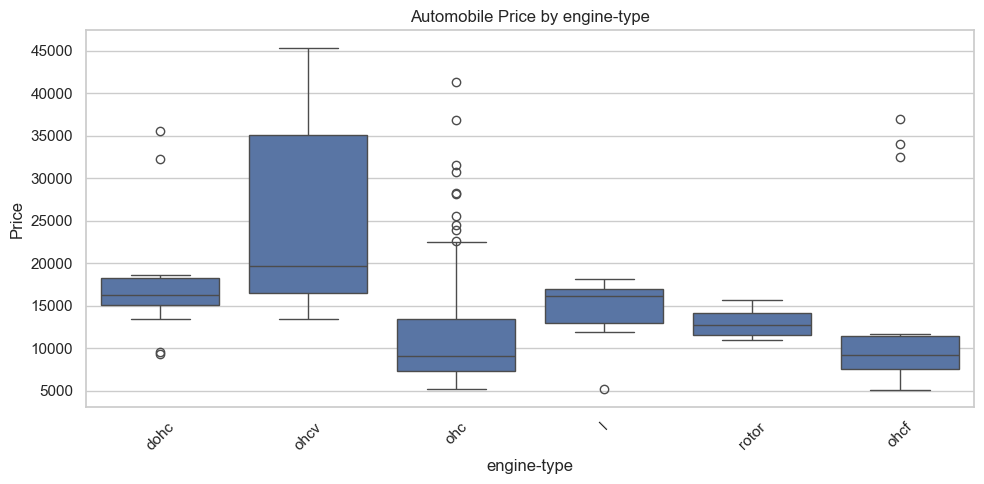

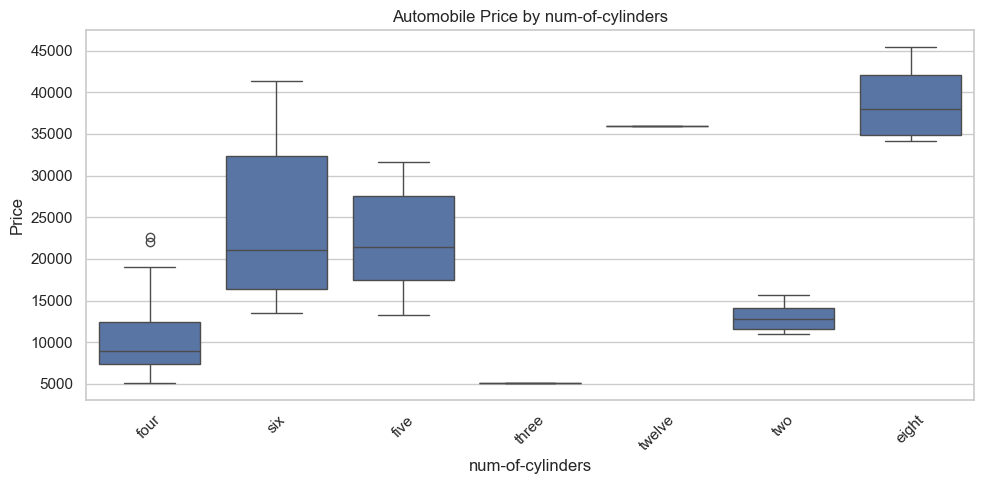

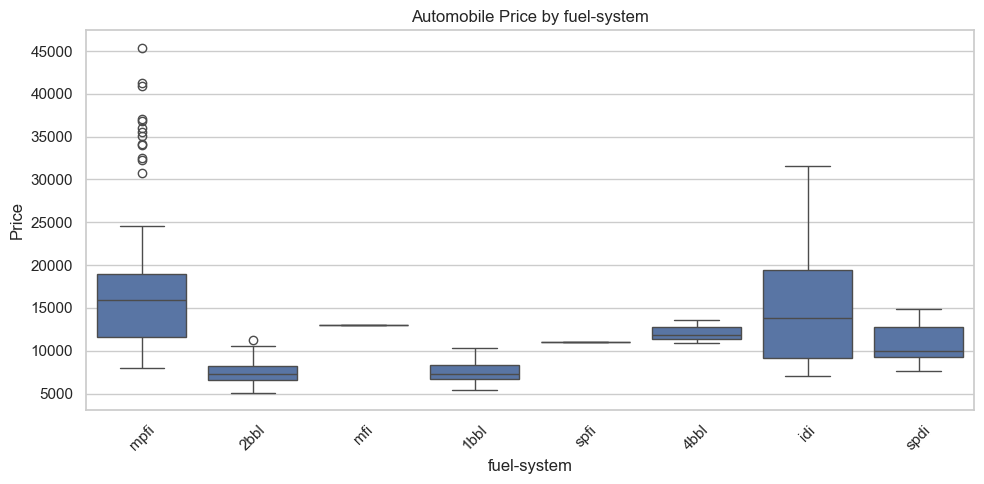

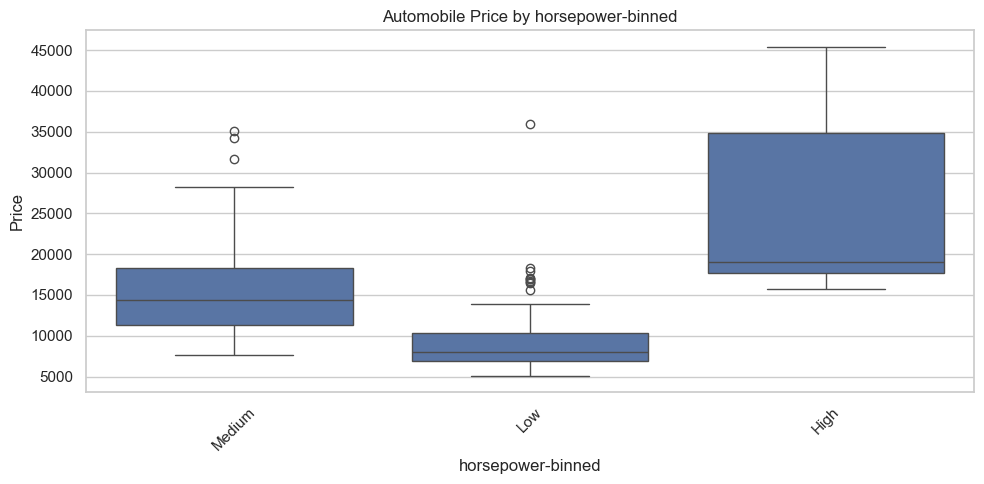

In [34]:
for column in categorical_vars:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x=column,
        y="price"
    )

    plt.title(f"Automobile Price by {column}")
    plt.xlabel(column)
    plt.ylabel("Price")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

#### (c) Two categorical variables

In [36]:
# Group by drive-wheels and body-style
two_category_stats = df.groupby(
    ["drive-wheels", "body-style"],
    observed=True
)["price"].agg(
    Average_Price="mean",
    Median_Price="median",
    Number_of_Cars="count"
).round(2).reset_index()

display(
    two_category_stats.sort_values(
        by="Average_Price",
        ascending=False
    )
)

,drive-wheels,body-style,Average_Price,Median_Price,Number_of_Cars
9,rwd,hardtop,24202.71,28176.0,7
8,rwd,convertible,23949.60,17669.0,5
11,rwd,sedan,21711.83,18382.0,36
12,rwd,wagon,16994.22,16515.0,9
10,rwd,hatchback,14337.78,14645.0,18
1,4wd,sedan,12647.33,11259.0,3
3,fwd,convertible,11595.00,11595.0,1
7,fwd,wagon,9997.33,8921.0,12
6,fwd,sedan,9811.80,8558.0,55
2,4wd,wagon,9095.75,8395.5,4


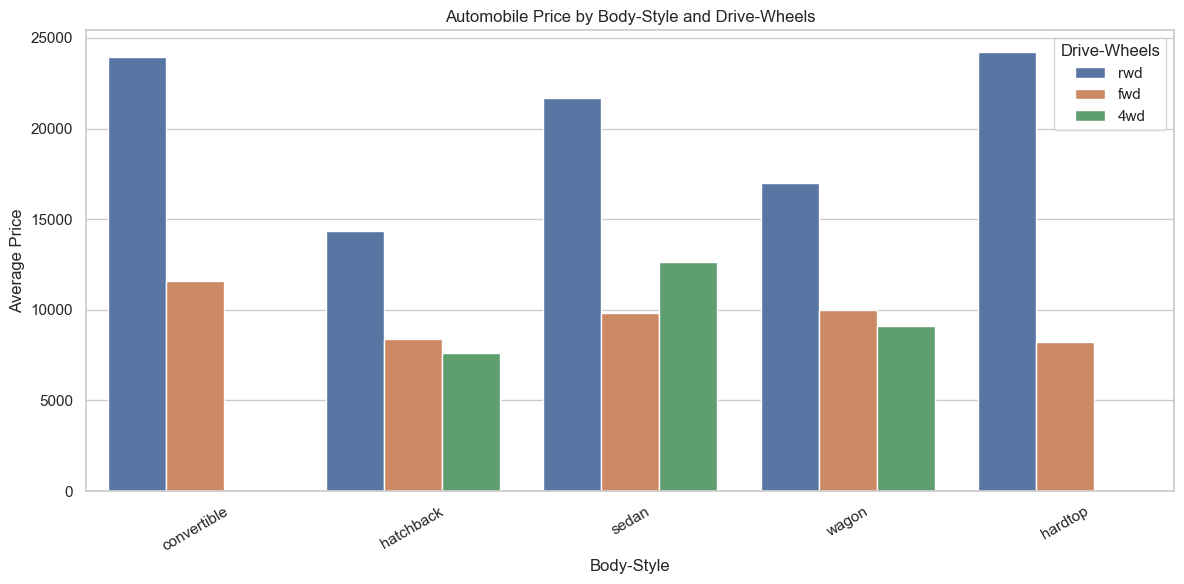

In [37]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="body-style",
    y="price",
    hue="drive-wheels",
    errorbar=None
)

plt.title("Automobile Price by Body-Style and Drive-Wheels")
plt.xlabel("Body-Style")
plt.ylabel("Average Price")
plt.legend(title="Drive-Wheels")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

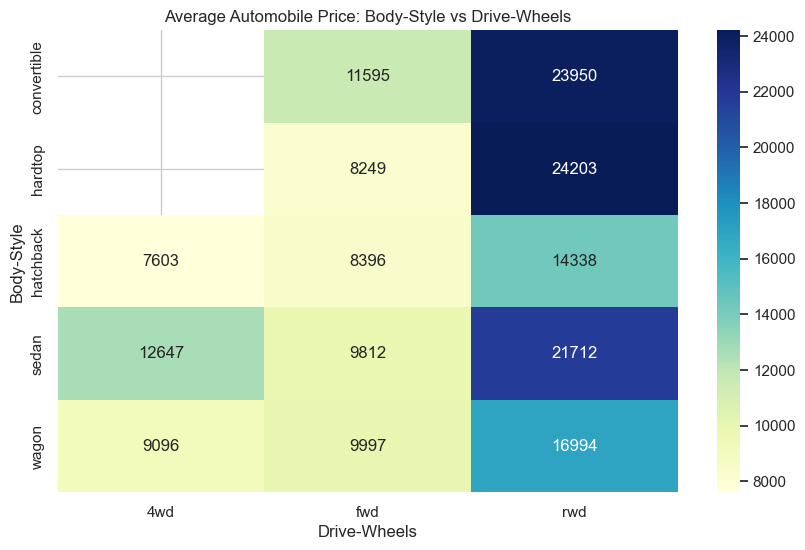

In [38]:
# Calculate average price for each combination
price_pivot = df.pivot_table(
    values="price",
    index="body-style",
    columns="drive-wheels",
    aggfunc="mean"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    price_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Average Automobile Price: Body-Style vs Drive-Wheels")
plt.xlabel("Drive-Wheels")
plt.ylabel("Body-Style")
plt.show()

### *Question 5.* Based on your findings, identify the main variables that have the most impact on car price, and support your answer with a feature selection method. Write a short recommendation for a car dealer setting prices.

In [39]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Load dataset
df = pd.read_csv("Kamutungye_Data.csv")

# Separate predictors and target
X = df.drop(columns=["price"])
y = pd.to_numeric(df["price"], errors="coerce")

# Remove rows with missing target values
valid_rows = y.notna() & (y > 0)
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Identify numerical and categorical variables
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocessing numerical and categorical variables
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Random Forest model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ))
])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)

print("R-squared:", round(r2_score(y_test, y_pred), 3))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))

# Extract feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract feature importance
importance = model.named_steps[
    "regressor"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

# Display top 10 features
top_features = importance_df.head(10)

display(top_features)

R-squared: 0.926
Mean Absolute Error: 1895.16


,Feature,Importance
6,num__curb-weight,0.430343
7,num__engine-size,0.277855
11,num__horsepower,0.056667
14,num__highway-mpg,0.050731
13,num__city-mpg,0.034217
15,num__city-L/100km,0.030727
4,num__width,0.029175
2,num__wheel-base,0.014558
20,cat__make_bmw,0.010437
3,num__length,0.008824


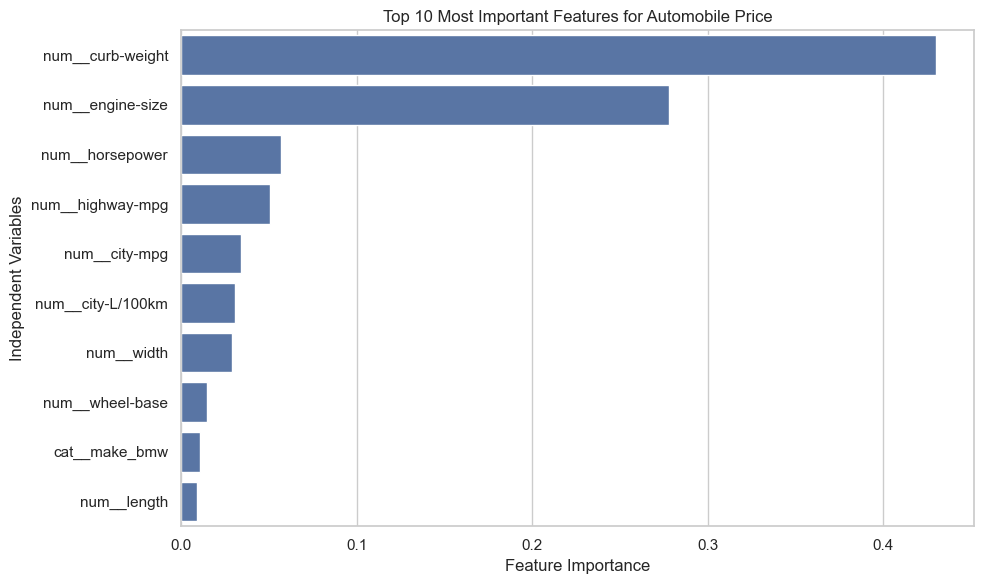

In [40]:
# Visualise the most important variables
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Most Important Features for Automobile Price")
plt.xlabel("Feature Importance")
plt.ylabel("Independent Variables")
plt.tight_layout()
plt.show()